# Classical segmentation of AF488 against Cellpose + a positivity rule

The cells analysis calls a cell AF488-positive in two steps: **Cellpose finds every nucleus** (on the nuclear stain), then each cell's AF488 is compared with a threshold — **median + 3 SD** of the region's cells (the default) or **ring contrast ≥ 1.5** (the cell over a ring 3–6 µm round its nucleus). The positive cell is therefore always *a nucleus grown by 3 µm*: whatever shape the labelled cell has, its outline is a blob.

The alternative asked here: **segment the AF488 signal itself** with a classical threshold, as Fiji or CellProfiler would. Two questions:

1. **Does it find the same positive cells?** Per sample (counts) and per cell (is a Cellpose cell that a rule calls positive covered by the AF488 mask, and the other way round?).
2. **Does it give more of the cell's structure** — cytoplasm, processes — than the nucleus-based outline?

**The classical pipeline** (`classical_vs_cellpose.py`, per sample, at full resolution, 0.325 µm a pixel):

- AF488 flattened over Z, smoothed (Gaussian, 0.5 µm);
- its **local background taken away** (Gaussian of 20 µm, computed at 1/4 resolution) — what a rolling ball does, so a bright region of tissue does not light up as a whole;
- thresholded **inside the tissue** (the nuclear stain's outline), three kinds of rule: **k × robust SD** of the background-subtracted tissue for k = 3, 5, 8 (`kmad3`, `kmad5`, `kmad8`), **triangle** (built for a histogram with one big peak and a long tail, which is what AF488 has) and **Otsu** (the classic two-group split);
- objects under 20 µm² dropped, holes under 10 µm² filled.

**Third Cellpose rule.** **Median + 7 SD on the median-filtered channel** (the channel less its local median over 45 µm; `count_cells.less_local_median`) — the rule `positivity_metrics` found best on 21 October, first without clicks and first against them. It is the baseline the AF488 masks have to beat.

**The comparison.** The Cellpose cells, nuclei and grown regions are the ones the cells analysis saved (the newest run of each sample); nothing is segmented again. A Cellpose cell is *covered* by a classical mask when the mask covers at least 25 % of its grown region (other shares are tried in section 2). Agreement is measured with **Cohen's κ** (0 = chance, 1 = identical calls).

Everything is computed by the script into `junction_eval/classical/` (≈15 s a sample, CPU only); this notebook only reads it.

In [1]:
from pathlib import Path
import json
import ssl
import sys
import warnings

try:
    ssl.create_default_context()
except ssl.SSLError:
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "microscopy_viewer").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

import classical_vs_cellpose as CV

RULES = ("median + 3 SD", "median + 7 SD (median filter)", "ring ≥ 1.5")
METHODS = CV.METHODS
MAIN = "kmad5"
NAMES = sorted(p.name for p in CV.OUT.iterdir() if (p / "summary.json").is_file())
SUMMARY = {n: json.loads((CV.OUT / n / "summary.json").read_text(encoding="utf-8")) for n in NAMES}
CELLS = {n: pd.read_parquet(CV.OUT / n / "cells.parquet") for n in NAMES}
OBJECTS = {(n, m): pd.read_parquet(CV.OUT / n / f"objects_{m}.parquet") for n in NAMES for m in METHODS}
for n in NAMES:
    for m in METHODS:
        CELLS[n][f"covered {m}"] = CELLS[n][f"cover {m}"].fillna(0) >= CV.COVER
print(f"{len(NAMES)} samples, {sum(len(c) for c in CELLS.values()):,} Cellpose cells; methods {METHODS}")

39 samples, 1,733,165 Cellpose cells; methods ('kmad3', 'kmad5', 'kmad8', 'triangle', 'otsu')


## 1. Counts per sample

Per sample: the cells each Cellpose rule calls positive, and the Cellpose cells each classical mask covers, in the whole section and in the junction region; and how many separate objects each classical mask has.

**How to read it.** If the classical masks found the same positive cells, the covered counts would track the rule's counts across samples (high Spearman ρ) at a similar level. The thresholds are in the image's own units after the background is taken away; *noise SD* is the robust spread of the background-subtracted tissue.

In [2]:
rows = []
for n in NAMES:
    c, s = CELLS[n], SUMMARY[n]
    region = c["In region"].astype(bool)
    row = {"sample": n.replace("2025_09_26_Asssembloid_", ""), "cells": len(c), "noise SD": round(s["noise_sd"], 1)}
    for r in RULES:
        row[f"{r}"] = int(c[r].sum())
        row[f"{r} (region)"] = int((c[r] & region).sum())
    for m in METHODS:
        row[f"{m} cells"] = int(c[f"covered {m}"].sum())
        row[f"{m} cells (region)"] = int((c[f"covered {m}"] & region).sum())
        row[f"{m} objects"] = len(OBJECTS[(n, m)])
    rows.append(row)
COUNTS = pd.DataFrame(rows).set_index("sample")
display(COUNTS[["cells", *RULES, *(f"{m} cells" for m in METHODS), *(f"{m} objects" for m in METHODS)]])

def rho(a, b):
    return stats.spearmanr(COUNTS[a], COUNTS[b]).correlation

counted = {**{r: r for r in RULES}, **{m: f"{m} cells" for m in METHODS}}
table = pd.DataFrame({
    name: {**{f"ρ vs {r}": rho(column, r) for r in RULES},
           **{f"ρ vs {r} (region)": rho(f"{column} (region)", f"{r} (region)") for r in RULES},
           **{f"× {r}": float(np.median(COUNTS[column] / COUNTS[r].clip(lower=1))) for r in RULES}}
    for name, column in counted.items()}).T
print("Spearman ρ of the per-sample counts, and the median ratio of counts (row ÷ column's rule):")
display(table.round(2))

,cells,median + 3 SD,median + 7 SD (median filter),ring ≥ 1.5,kmad3 cells,kmad5 cells,kmad8 cells,triangle cells,otsu cells,kmad3 objects,kmad5 objects,kmad8 objects,triangle objects,otsu objects
sample,,,,,,,,,,,,,,
018-017_s1,29590,1186,531,182,1130,568,315,230,3,632,330,192,147,3
018-017_s10,44201,3485,658,230,1664,665,305,302,6,798,363,166,161,7
018-017_s11,37445,3529,637,174,1322,507,220,230,1,672,301,156,166,2
018-017_s13,48036,1425,686,275,1856,767,316,799,203,850,390,191,403,134
018-017_s2,25033,865,443,112,1050,502,236,436,27,532,294,169,265,24
018-017_s3,21131,1796,404,124,817,383,220,351,39,436,224,138,218,32
018-017_s4,29771,1379,524,192,1109,541,278,290,1,569,326,188,196,1
018-017_s5,31218,2574,807,310,1346,618,279,481,34,648,384,202,326,35
018-017_s6,25476,2317,599,164,950,415,191,397,80,510,270,142,263,79


Spearman ρ of the per-sample counts, and the median ratio of counts (row ÷ column's rule):


,ρ vs median + 3 SD,ρ vs median + 7 SD (median filter),ρ vs ring ≥ 1.5,ρ vs median + 3 SD (region),ρ vs median + 7 SD (median filter) (region),ρ vs ring ≥ 1.5 (region),× median + 3 SD,× median + 7 SD (median filter),× ring ≥ 1.5
median + 3 SD,1.00,0.48,0.20,1.00,0.35,0.47,1.00,3.78,7.18
median + 7 SD (median filter),0.48,1.00,0.41,0.35,1.00,0.62,0.26,1.00,2.27
ring ≥ 1.5,0.20,0.41,1.00,0.47,0.62,1.00,0.14,0.44,1.00
kmad3,0.26,0.31,0.77,0.67,0.65,0.68,0.80,2.53,5.83
kmad5,0.21,0.39,0.79,0.52,0.85,0.72,0.31,1.11,2.38
kmad8,0.12,0.48,0.73,0.38,0.89,0.63,0.14,0.53,1.08
triangle,-0.10,0.14,0.51,0.41,0.78,0.74,0.20,0.66,1.32
otsu,-0.36,-0.11,0.27,0.23,0.39,0.44,0.01,0.05,0.12


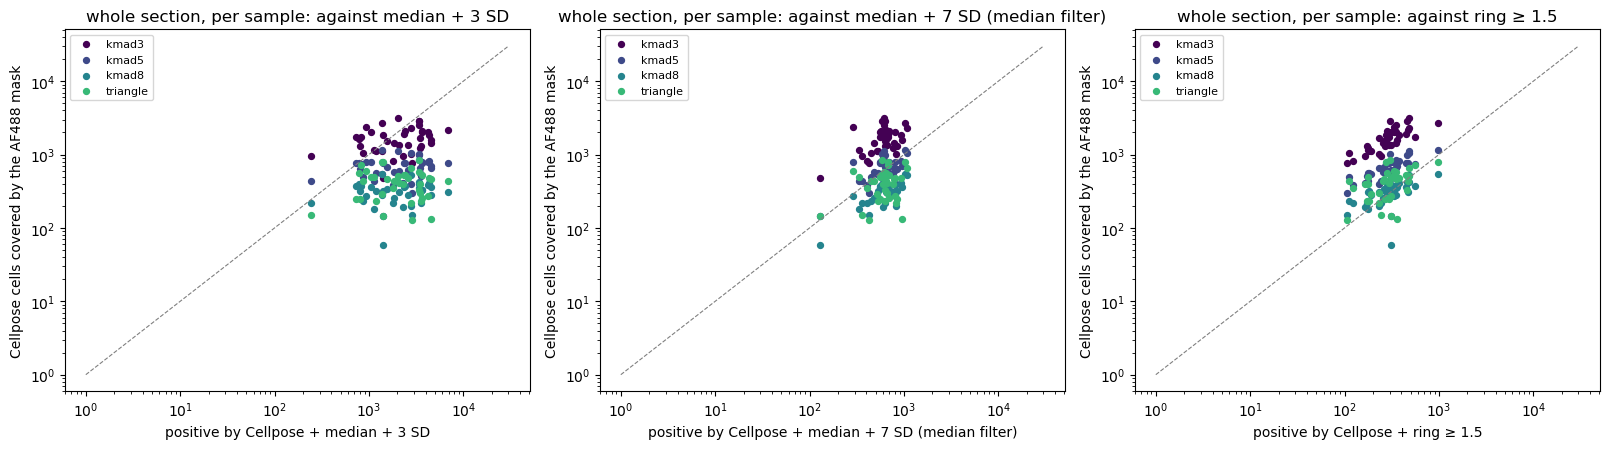

In [3]:
fig, axes = plt.subplots(1, len(RULES), figsize=(5.4 * len(RULES), 4.6))
for ax, rule in zip(axes, RULES):
    for m, colour in zip(METHODS, plt.cm.viridis(np.linspace(0, 0.9, len(METHODS)))):
        if m == "otsu":
            continue
        ax.scatter(COUNTS[rule].clip(lower=1), COUNTS[f"{m} cells"].clip(lower=1), s=18, color=colour, label=m)
    lim = [1, max(COUNTS[[rule, *(f"{m} cells" for m in METHODS)]].max()) * 1.5]
    ax.plot(lim, lim, color="grey", lw=0.8, ls="--")
    ax.set(xscale="log", yscale="log", xlabel=f"positive by Cellpose + {rule}", ylabel="Cellpose cells covered by the AF488 mask",
           title=f"whole section, per sample: against {rule}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Cell by cell

Pooled over every sample: for each Cellpose rule and each classical mask, how many cells each calls positive, how many both do, the share of the rule's positives the mask covers (*rule's found by mask*), the share of covered cells the rule calls positive (*mask's called by rule*), and Cohen's κ. The last column is κ's median over samples, so one large sample does not decide it.

In [4]:
def kappa(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    po = np.mean(a == b)
    pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return (po - pe) / (1 - pe) if pe < 1 else np.nan

ALL = pd.concat([CELLS[n].assign(sample=n) for n in NAMES], ignore_index=True)
rows = []
for r in RULES:
    for m in METHODS:
        a, b = ALL[r].to_numpy(bool), ALL[f"covered {m}"].to_numpy(bool)
        rows.append({"rule": r, "mask": m, "rule +": int(a.sum()), "mask covers": int(b.sum()), "both": int((a & b).sum()),
                     "rule's found by mask": (a & b).sum() / max(a.sum(), 1), "mask's called by rule": (a & b).sum() / max(b.sum(), 1),
                     "κ pooled": kappa(a, b),
                     "κ median per sample": np.nanmedian([kappa(CELLS[n][r], CELLS[n][f"covered {m}"]) for n in NAMES])})
for i, r in enumerate(RULES):
    for other in RULES[i + 1:]:
        a, b = ALL[r].to_numpy(bool), ALL[other].to_numpy(bool)
        rows.append({"rule": r, "mask": f"({other})", "rule +": int(a.sum()), "mask covers": int(b.sum()), "both": int((a & b).sum()),
                     "rule's found by mask": (a & b).sum() / max(a.sum(), 1), "mask's called by rule": (a & b).sum() / max(b.sum(), 1),
                     "κ pooled": kappa(a, b), "κ median per sample": np.nanmedian([kappa(CELLS[n][r], CELLS[n][other]) for n in NAMES])})
AGREE = pd.DataFrame(rows)
display(AGREE.round(3))

,rule,mask,rule +,mask covers,both,rule's found by mask,mask's called by rule,κ pooled,κ median per sample
0,median + 3 SD,kmad3,93888,65639,31996,0.341,0.487,0.373,0.373
1,median + 3 SD,kmad5,93888,26638,18797,0.200,0.706,0.295,0.292
2,median + 3 SD,kmad8,93888,12260,10994,0.117,0.897,0.197,0.201
3,median + 3 SD,triangle,93888,16539,13103,0.140,0.792,0.225,0.263
4,median + 3 SD,otsu,93888,25726,4318,0.046,0.168,0.050,0.026
5,median + 7 SD (median filter),kmad3,24747,65639,22983,0.929,0.350,0.498,0.536
6,median + 7 SD (median filter),kmad5,24747,26638,20376,0.823,0.765,0.790,0.802
7,median + 7 SD (median filter),kmad8,24747,12260,12130,0.490,0.989,0.652,0.685
8,median + 7 SD (median filter),triangle,24747,16539,14785,0.597,0.894,0.713,0.748
9,median + 7 SD (median filter),otsu,24747,25726,3820,0.154,0.148,0.139,0.090


**How much the 25 % coverage matters.** The same comparison for the main mask (`kmad5`) with a cell counted as covered from 5 % to 90 % of its grown region on.

In [5]:
shares = (0.05, 0.1, 0.25, 0.5, 0.75, 0.9)
rows = []
for share in shares:
    covered = ALL[f"cover {MAIN}"].fillna(0).to_numpy() >= share
    rows.append({"covered from": share, "cells covered": int(covered.sum()),
                 **{f"κ vs {r}": kappa(ALL[r], covered) for r in RULES},
                 **{f"{r}'s found": (ALL[r].to_numpy(bool) & covered).sum() / max(ALL[r].sum(), 1) for r in RULES}})
display(pd.DataFrame(rows).round(3))

,covered from,cells covered,κ vs median + 3 SD,κ vs median + 7 SD (median filter),κ vs ring ≥ 1.5,median + 3 SD's found,median + 7 SD (median filter)'s found,ring ≥ 1.5's found
0,0.05,53103,0.327,0.565,0.258,0.276,0.902,0.710
1,0.10,44088,0.328,0.637,0.296,0.258,0.895,0.699
2,0.25,26638,0.295,0.790,0.408,0.200,0.823,0.656
3,0.50,11680,0.185,0.609,0.493,0.110,0.451,0.484
4,0.75,4633,0.086,0.306,0.361,0.047,0.183,0.250
5,0.90,2128,0.041,0.154,0.213,0.022,0.085,0.126


## 3. Do they tell the same story about where the positive cells are?

The share of cells positive against their distance to the junction line (negative: across the line from the band's side), pooled over every sample, for each Cellpose rule and for the cells the classical masks cover. What matters downstream is the shape of these curves — a step at the line, a tail into the other organoid — more than their height.

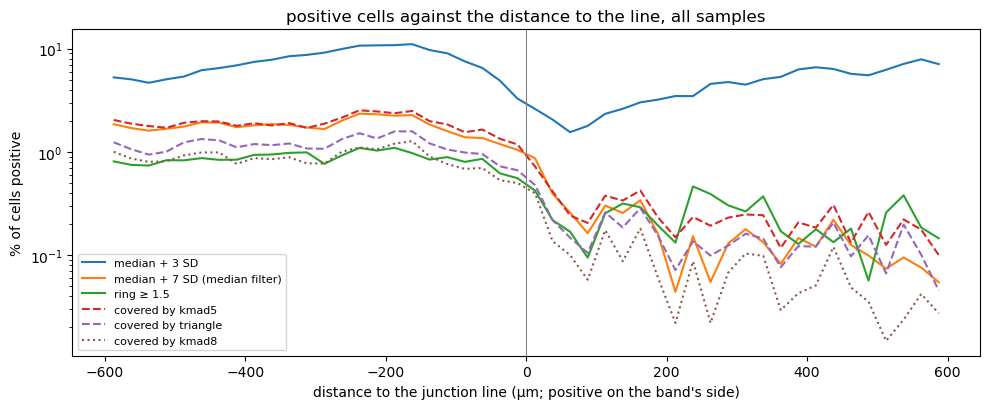

In [6]:
edges = np.arange(-600, 601, 25.0)
mid = (edges[:-1] + edges[1:]) / 2
d = ALL["Distance to the junction line (µm)"].to_numpy(float)
fig, ax = plt.subplots(figsize=(10, 4.2))
for label, column, style in [("median + 3 SD", "median + 3 SD", "-"), ("median + 7 SD (median filter)", "median + 7 SD (median filter)", "-"),
                             ("ring ≥ 1.5", "ring ≥ 1.5", "-"),
                             (f"covered by {MAIN}", f"covered {MAIN}", "--"), ("covered by triangle", "covered triangle", "--"),
                             ("covered by kmad8", "covered kmad8", ":")]:
    v = ALL[column].to_numpy(bool)
    share = [100 * v[(d >= a) & (d < b)].mean() if ((d >= a) & (d < b)).sum() > 200 else np.nan for a, b in zip(edges[:-1], edges[1:])]
    ax.plot(mid, share, style, label=label)
ax.axvline(0, color="grey", lw=0.8)
ax.set(xlabel="distance to the junction line (µm; positive on the band's side)", ylabel="% of cells positive", yscale="log",
       title="positive cells against the distance to the line, all samples")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Shape: does thresholding the label give more of the cell?

Per classical mask, pooled over samples: the objects it finds, their size, their **skeleton length** (the length of the object's centre line — long for a cell with processes, short for a round blob), their **solidity** (area over convex hull: 1 for a convex blob, low for a branched or ragged shape), how many Cellpose nuclei each touches (0: signal with no nucleus under it — a process, a fragment or debris; 2 or more: neighbouring cells merged into one object), and how much of the mask lies **outside every nucleus** and **outside every grown region** (nucleus + 3 µm, the area the rules measure over).

For comparison, a Cellpose positive cell's outline is its nucleus grown by 3 µm: the last row gives the median nucleus area of the cells median + 3 SD calls positive.

**Two of these numbers mislead on their own.** The image is flattened over Z (maximum of the planes), so a labelled cell or process lying above or below unlabelled nuclei *touches* them in 2D: "nuclei touched" counts overlaps in the flattened image, not cells merged. And in dense tissue the grown regions (every nucleus + 3 µm, split between neighbours) tile almost all of it, so "outside grown regions" is near zero whatever the mask's shape. The share **outside nuclei** and the **skeleton length** are the ones that say whether the mask holds more than the nucleus; the pictures in section 5 say it best.

In [7]:
rows = []
for m in METHODS:
    o = pd.concat([OBJECTS[(n, m)] for n in NAMES if len(OBJECTS[(n, m)])], ignore_index=True)
    areas = {k: sum(SUMMARY[n]["mask_areas"][m][k] for n in NAMES) for k in ("mask_area_um2", "outside_nuclei_um2", "outside_cells_um2")}
    rows.append({"mask": m, "objects": len(o), "median area (µm²)": o["Area (µm²)"].median(), "P90 area (µm²)": o["Area (µm²)"].quantile(0.9),
                 "median skeleton (µm)": o["Skeleton (µm)"].median(), "P90 skeleton (µm)": o["Skeleton (µm)"].quantile(0.9),
                 "median solidity": o["Solidity"].median(),
                 "% touching 0 nuclei": 100 * (o["Nuclei touched"] == 0).mean(), "% touching 1": 100 * (o["Nuclei touched"] == 1).mean(),
                 "% touching ≥ 2": 100 * (o["Nuclei touched"] >= 2).mean(),
                 "% of mask outside nuclei": 100 * areas["outside_nuclei_um2"] / max(areas["mask_area_um2"], 1),
                 "% of mask outside grown regions": 100 * areas["outside_cells_um2"] / max(areas["mask_area_um2"], 1)})
SHAPE = pd.DataFrame(rows).set_index("mask")
display(SHAPE.round(1))
pos = ALL[ALL["median + 3 SD"]]
print(f"Cellpose, median + 3 SD positives: median nucleus area {pos['Nucleus area (µm²)'].median():.0f} µm² "
      f"(grown by 3 µm ≈ {np.pi * (np.sqrt(pos['Nucleus area (µm²)'].median() / np.pi) + 3) ** 2:.0f} µm²)")

,objects,median area (µm²),P90 area (µm²),median skeleton (µm),P90 skeleton (µm),median solidity,% touching 0 nuclei,% touching 1,% touching ≥ 2,% of mask outside nuclei,% of mask outside grown regions
mask,,,,,,,,,,,
kmad3,31149,50.0,176.8,10.1,32.5,0.9,8.0,17.3,74.7,62.2,9.0
kmad5,16049,45.7,139.7,8.1,23.4,0.9,9.0,19.4,71.6,60.4,9.8
kmad8,8434,42.8,119.9,7.2,19.5,0.9,9.3,21.9,68.8,58.6,10.4
triangle,10847,43.9,128.3,7.5,21.1,0.9,9.7,21.1,69.2,59.1,9.0
otsu,7036,50.9,233.9,11.0,50.9,0.8,8.2,15.6,76.2,59.7,9.0


Cellpose, median + 3 SD positives: median nucleus area 20 µm² (grown by 3 µm ≈ 97 µm²)


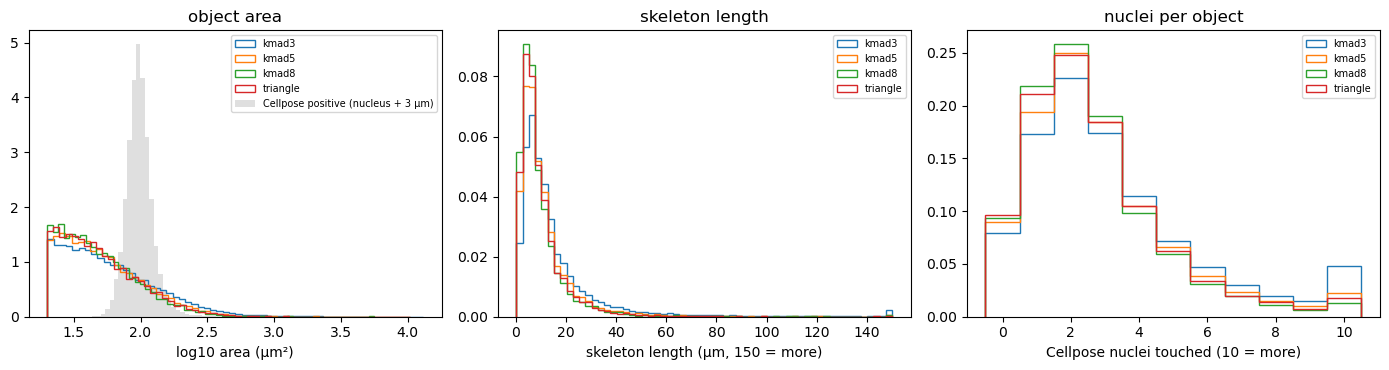

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for m in ("kmad3", MAIN, "kmad8", "triangle"):
    o = pd.concat([OBJECTS[(n, m)] for n in NAMES], ignore_index=True)
    axes[0].hist(np.log10(o["Area (µm²)"]), bins=60, histtype="step", density=True, label=m)
    axes[1].hist(o["Skeleton (µm)"].clip(upper=150), bins=60, histtype="step", density=True, label=m)
    axes[2].hist(o["Nuclei touched"].clip(upper=10), bins=np.arange(12) - 0.5, histtype="step", density=True, label=m)
grown = np.log10(np.pi * (np.sqrt(pos["Nucleus area (µm²)"] / np.pi) + 3) ** 2)
axes[0].hist(grown, bins=60, histtype="stepfilled", alpha=0.25, density=True, color="grey", label="Cellpose positive (nucleus + 3 µm)")
axes[0].set(xlabel="log10 area (µm²)", title="object area")
axes[1].set(xlabel="skeleton length (µm, 150 = more)", title="skeleton length")
axes[2].set(xlabel="Cellpose nuclei touched (10 = more)", title="nuclei per object")
for ax in axes:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 5. Pictures

For two samples: 60 µm crops of AF488 (each crop stretched on its own, so brightness cannot be compared between crops), the **`kmad5` mask outlined in yellow** and the **Cellpose nucleus of the centre cell outlined in cyan**. Rows:

- **both** — positive by median + 3 SD and covered by the mask;
- **mask only** — covered by the mask, negative by both Cellpose rules;
- **rule only** — positive by median + 3 SD, the mask covers under 5 % of it;
- **largest objects** — the mask's objects with the longest skeleton: where the shape of the labelled cells shows, or cells merge.

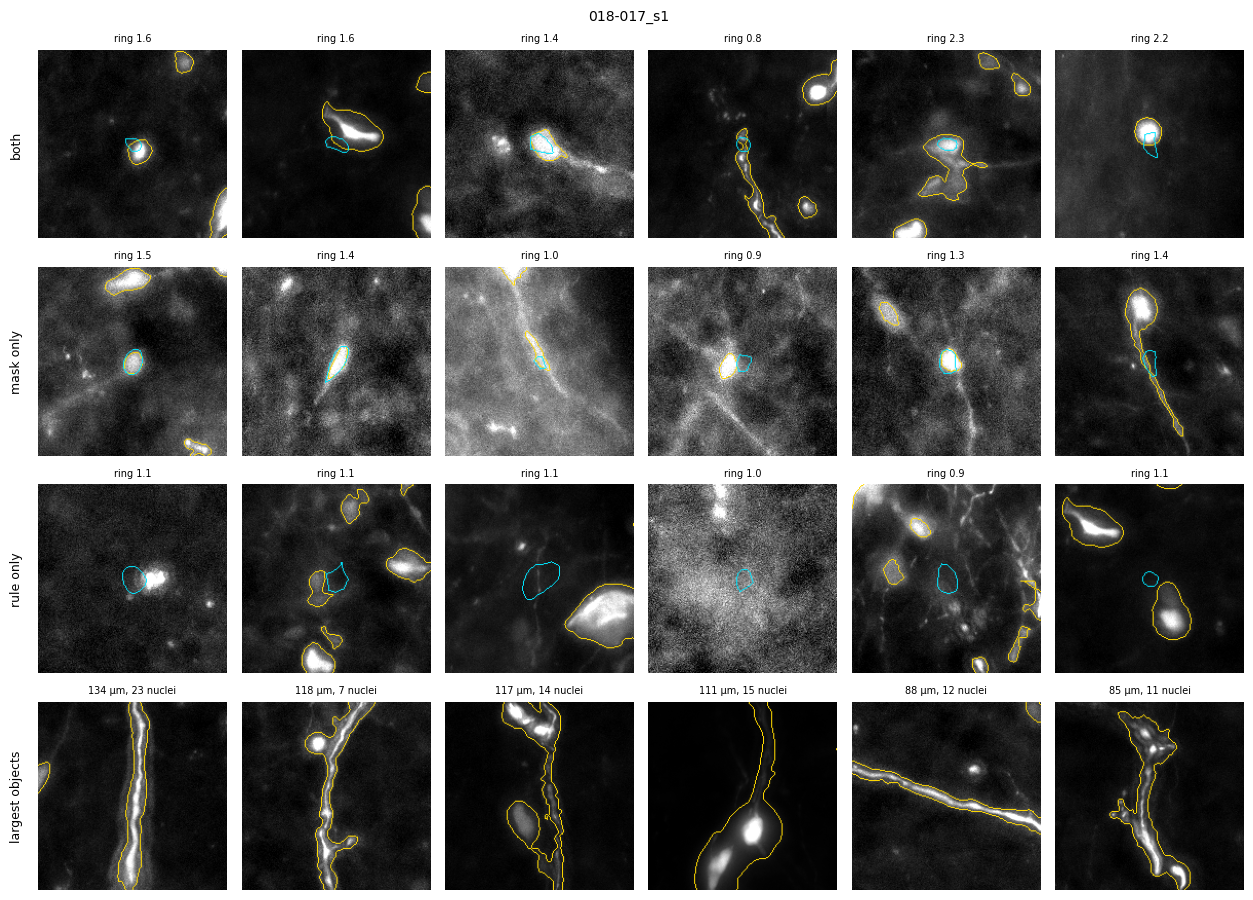

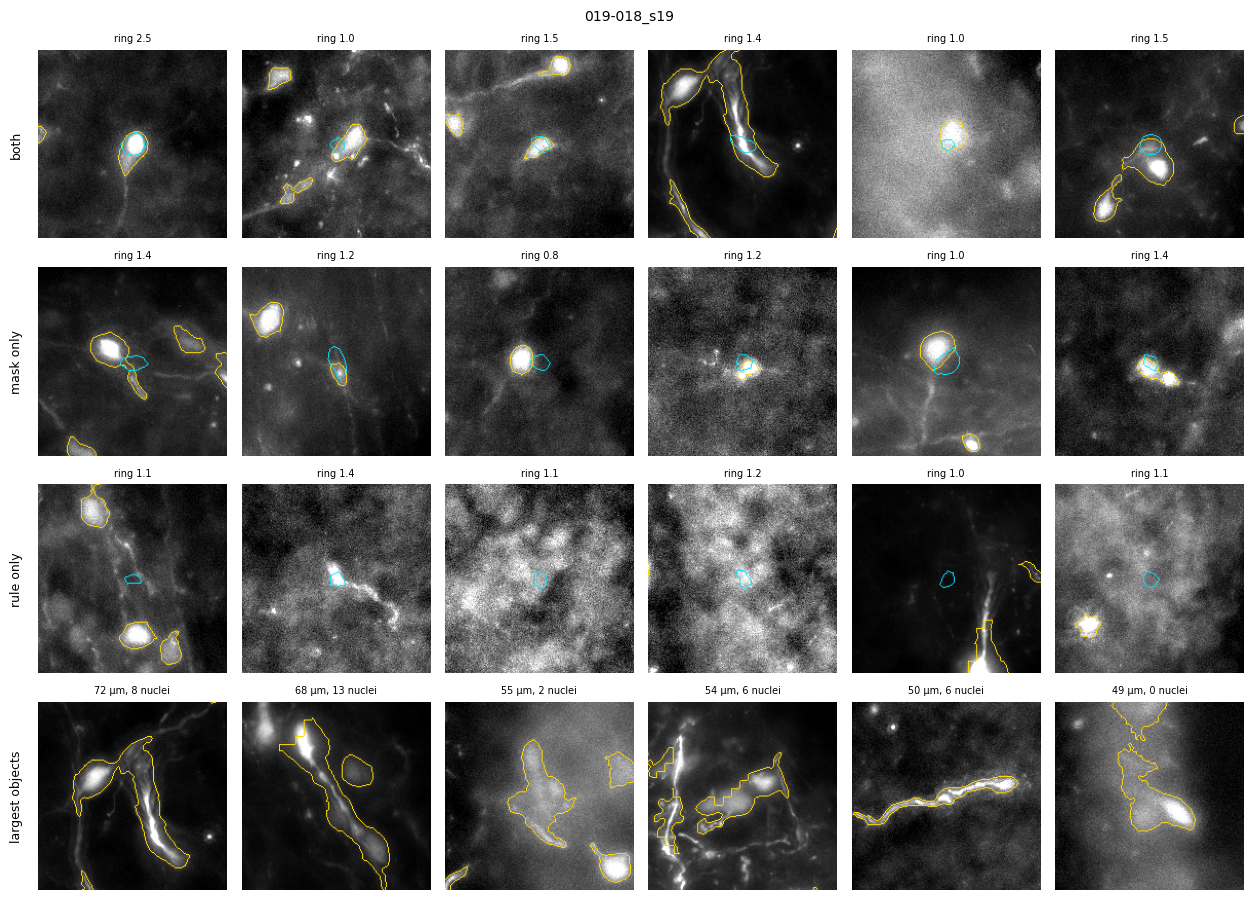

In [9]:
from microscopy_viewer import junction_analysis as ja
from microscopy_viewer import loaders
from skimage.segmentation import find_boundaries
import tifffile

HALF_UM = 30.0
rng = np.random.default_rng(0)


def gallery(name, per_row=6):
    s, c = SUMMARY[name], CELLS[name]
    voxel = s["voxel_um"]
    half = int(HALF_UM / voxel)
    specs = loaders.load_path(Path(s["file"]))
    try:
        names = [str(sp.channel_name or sp.name) for sp in specs]
        i488 = next(i for i, nm in enumerate(names) if "488" in nm)
        whole = (slice(0, s["shape"][0]), slice(0, s["shape"][1]))
        af488 = ja._plane(specs[i488], whole).astype(np.float32)
    finally:
        loaders.release(Path(s["file"]))
    mask = tifffile.imread(CV.OUT / name / f"{MAIN}.tif") > 0
    run = Path(s["run"])
    nuclei = ja.read_labels(run / "labels" / f"{name} nuclei.tif")
    objects = OBJECTS[(name, MAIN)]
    picks = {
        "both": c[c["median + 3 SD"] & c[f"covered {MAIN}"]],
        "mask only": c[c[f"covered {MAIN}"] & ~c["median + 3 SD"] & ~c["ring ≥ 1.5"]],
        "rule only": c[c["median + 3 SD"] & (c[f"cover {MAIN}"].fillna(0) < 0.05)],
        "largest objects": objects.nlargest(per_row, "Skeleton (µm)"),
    }
    fig, axes = plt.subplots(len(picks), per_row, figsize=(2.1 * per_row, 2.3 * len(picks)))
    for row, (title, table) in enumerate(picks.items()):
        chosen = table if len(table) <= per_row or title == "largest objects" else table.iloc[rng.choice(len(table), per_row, replace=False)]
        for col in range(per_row):
            ax = axes[row, col]
            ax.axis("off")
            if col >= len(chosen):
                continue
            item = chosen.iloc[col]
            y, x = int(item["Centroid Y (µm)"] / voxel), int(item["Centroid X (µm)"] / voxel)
            win = (slice(max(y - half, 0), y + half), slice(max(x - half, 0), x + half))
            crop = af488[win]
            lo, hi = np.percentile(crop, (1, 99.5))
            rgb = np.repeat(np.clip((crop - lo) / max(hi - lo, 1), 0, 1)[..., None], 3, axis=2)
            rgb[find_boundaries(mask[win], mode="inner")] = (1.0, 0.85, 0.0)
            if "Label" in item:
                rgb[find_boundaries(nuclei[win] == int(item["Label"]), mode="inner")] = (0.0, 0.9, 1.0)
            ax.imshow(rgb)
            if "ring" in str(item.index.tolist()) and "AF488 ring contrast" in item:
                ax.set_title(f"ring {item['AF488 ring contrast']:.1f}", fontsize=7)
            elif "Skeleton (µm)" in item:
                ax.set_title(f"{item['Skeleton (µm)']:.0f} µm, {int(item['Nuclei touched'])} nuclei", fontsize=7)
        axes[row, 0].text(-0.08, 0.5, title, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
    fig.suptitle(name.replace("2025_09_26_Asssembloid_", ""), fontsize=10)
    plt.tight_layout()
    plt.show()


for name in [NAMES[0], NAMES[len(NAMES) // 2]]:
    gallery(name)

## 6. Against Quillan's clicks

The previous baseline: the clicks Quillan made on 12 samples of the earlier annotated set, scored exactly as in `positivity_metrics` — in **his region** (cells within 50 µm of his line either side, or past it), each click matched one to one to the nearest Cellpose cell within 7 µm:

- **TP** — positive cells in the region that were clicked; **FP** — positive cells in the region not clicked; **FN** — clicks in the region whose cell is not positive, plus clicks that matched no cell;
- **precision**, **recall**, **F1** pooled over the samples; per sample, the count per mm of line against the clicks per mm: **Spearman** (same ranking?), **CCC** (same numbers?), **median ratio** (count ÷ clicks).

These samples' Cellpose cells are the ones `count_cells.py` measured (no label maps were kept), so here a cell counts as covered by an AF488 mask when the mask fills at least 25 % of a 6 µm square on its centre — the size of a nucleus grown by 3 µm — rather than of its grown region.

Two more columns need no Cellpose cell at all: **clicks on the mask** — the share of the region's clicks with mask within 3 µm of them; and the same for a click count of its own, so a missed segmentation does not count against the mask.

The clicks are noisy and incomplete (Quillan's own words): recall is the more trustworthy figure.

In [10]:
import count_common as C
from scipy import ndimage

cells_c, meta_c = C.load_all(progress=False)
LABEL = C.label_channel(meta_c)
RULES_C = C.rules(meta_c["channels"].iloc[0], LABEL)
WANTED = {"median + 3 SD": "band median + 3 SD (current)", "median + 7 SD (median filter)": "band median + 7 SD, median filter",
          "ring ≥ 1.5": "ring contrast ≥ 1.5"}
dots = C.load_dots(cells_c, meta_c)
CLICKED = sorted(n for n in dots["name"].unique() if (CV.OUT_CLICKED / n / "summary.json").is_file())
print(f"{len(CLICKED)} clicked samples with masks, {int(dots['name'].isin(CLICKED).sum())} clicks")


def length_mm(n, band):
    return meta_c.loc[n, "lengths (um)"].get(band, np.nan) / 1000


def click_region(n):
    # As positivity_metrics: Quillan's region, its band, the clicks in it (with their cell, -1 if none).
    df = cells_c[n]
    band = "second" if "in second" in df else "first"
    reg = C.region(df, "near + crossed", band, LABEL)
    d = dots[dots["name"] == n].copy()
    sign = -1.0 if C.home_is_band_side(df, LABEL, band) else 1.0
    away = sign * d[f"from {band} (um)"].to_numpy()
    own = d[f"beside {band}"].to_numpy().astype(bool) & ((away > C.GAP_UM) | (np.abs(away) <= 50))
    cell = d["cell"].to_numpy()
    d["in region"] = np.where(cell >= 0, reg[np.clip(cell, 0, None)], own)
    return band, reg, d[d["in region"]]


rows, near = [], []
for n in CLICKED:
    df = cells_c[n]
    band, reg, d = click_region(n)
    clicked = df["clicked"].to_numpy()
    cell = d["cell"].to_numpy()
    voxel = float(meta_c.loc[n, "voxel"][0])
    calls = {name: np.asarray(RULES_C[rule](df, band), bool) for name, rule in WANTED.items()}
    ys, xs = df["y"].to_numpy(), df["x"].to_numpy()
    for m in METHODS:
        mask = tifffile.imread(CV.OUT_CLICKED / n / f"{m}.tif") > 0
        box = ndimage.uniform_filter(mask.astype(np.float32), size=int(round(6.0 / voxel)) | 1)
        rr = np.clip(np.round(ys).astype(int), 0, mask.shape[0] - 1)
        cc_ = np.clip(np.round(xs).astype(int), 0, mask.shape[1] - 1)
        calls[f"AF488 mask {m}"] = box[rr, cc_] >= CV.COVER
        reach = ndimage.maximum_filter(mask, size=int(round(6.0 / voxel)) | 1)
        dy = np.clip(np.round(d["y (um)"].to_numpy() / voxel).astype(int), 0, mask.shape[0] - 1)
        dx = np.clip(np.round(d["x (um)"].to_numpy() / voxel).astype(int), 0, mask.shape[1] - 1)
        near.append({"name": n, "mask": m, "clicks": len(d), "on mask": int(reach[dy, dx].sum())})
    for name, p in calls.items():
        pr = p & reg
        rows.append({"name": n, "rule": name, "mm": length_mm(n, band),
                     "TP": int((pr & clicked).sum()), "FP": int((pr & ~clicked).sum()),
                     "FN": int(((cell < 0) | ~p[np.clip(cell, 0, None)]).sum()),
                     "positive": int(pr.sum()), "clicks": len(d)})
CLICKS = pd.DataFrame(rows)
NEAR = pd.DataFrame(near)

summary = []
for name, g in CLICKS.groupby("rule", sort=False):
    tp, fp, fn = g["TP"].sum(), g["FP"].sum(), g["FN"].sum()
    precision, recall = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    per_mm, clicks_mm = g["positive"] / g["mm"], g["clicks"] / g["mm"]
    row = {"rule": name, "positive in region": int(g["positive"].sum()), "TP": int(tp), "FP": int(fp), "FN": int(fn),
           "precision": precision, "recall": recall, "F1": 2 * precision * recall / max(precision + recall, 1e-9),
           "Spearman vs clicks / mm": stats.spearmanr(per_mm, clicks_mm).correlation,
           "CCC vs clicks / mm": C.ccc(per_mm, clicks_mm), "median ratio (count ÷ clicks)": float(np.median(g["positive"] / g["clicks"].clip(lower=1)))}
    m = name.replace("AF488 mask ", "")
    if m in METHODS:
        hits = NEAR[NEAR["mask"] == m]
        row["clicks on the mask"] = hits["on mask"].sum() / max(hits["clicks"].sum(), 1)
    summary.append(row)
CLICK_SCORES = pd.DataFrame(summary).set_index("rule")
display(CLICK_SCORES.round(3))

12 clicked samples with masks, 822 clicks


,positive in region,TP,FP,FN,precision,recall,F1,Spearman vs clicks / mm,CCC vs clicks / mm,median ratio (count ÷ clicks),clicks on the mask
rule,,,,,,,,,,,
median + 3 SD,5686,348,5338,265,0.061,0.568,0.110,0.280,0.034,7.250,NaN
median + 7 SD (median filter),1295,330,965,283,0.255,0.538,0.346,0.790,0.291,1.444,NaN
ring ≥ 1.5,1035,192,843,421,0.186,0.313,0.233,0.622,0.381,1.323,NaN
AF488 mask kmad3,7760,410,7350,203,0.053,0.669,0.098,0.483,0.026,6.680,0.829
AF488 mask kmad5,2548,341,2207,272,0.134,0.556,0.216,0.615,0.093,1.832,0.711
AF488 mask kmad8,1152,245,907,368,0.213,0.400,0.278,0.713,0.254,0.815,0.532
AF488 mask triangle,1175,285,890,328,0.243,0.465,0.319,0.608,0.298,1.142,0.607
AF488 mask otsu,7156,93,7063,520,0.013,0.152,0.024,0.458,-0.007,0.149,0.204


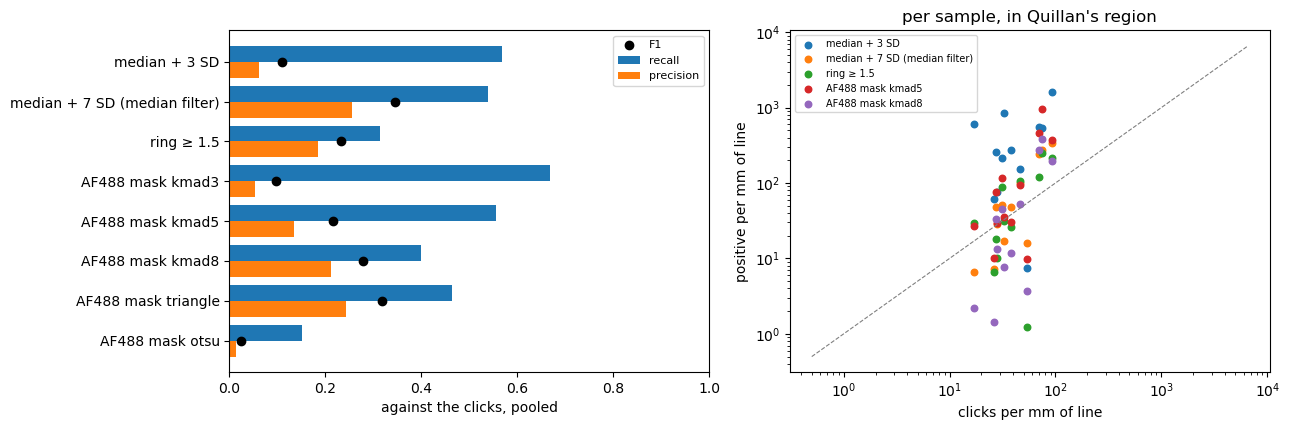

In [11]:
order = list(CLICK_SCORES.index)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
y = np.arange(len(order))
axes[0].barh(y - 0.2, CLICK_SCORES["recall"], 0.4, label="recall")
axes[0].barh(y + 0.2, CLICK_SCORES["precision"], 0.4, label="precision")
axes[0].scatter(CLICK_SCORES["F1"], y, color="black", zorder=3, label="F1")
axes[0].set(yticks=y, yticklabels=order, xlabel="against the clicks, pooled", xlim=(0, 1))
axes[0].invert_yaxis()
axes[0].legend(fontsize=8)
for name, colour in zip(["median + 3 SD", "median + 7 SD (median filter)", "ring ≥ 1.5", f"AF488 mask {MAIN}", "AF488 mask kmad8"],
                        ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]):
    g = CLICKS[CLICKS["rule"] == name]
    axes[1].scatter(g["clicks"] / g["mm"], g["positive"] / g["mm"], color=colour, label=name, s=22)
lim = [0.5, float((CLICKS["positive"] / CLICKS["mm"]).max()) * 1.3]
axes[1].plot(lim, lim, color="grey", lw=0.8, ls="--")
axes[1].set(xscale="log", yscale="log", xlabel="clicks per mm of line", ylabel="positive per mm of line", title="per sample, in Quillan's region")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Pictures against the clicks.** For two clicked samples: 40 µm crops of AF488 round clicks and cells in Quillan's region, the `kmad5` mask in yellow, the click (or the cell's centre) as a red cross. Rows: clicked and on the mask; clicked, not on the mask; on the mask (a covered cell), not clicked; positive by median + 7 SD, not clicked.

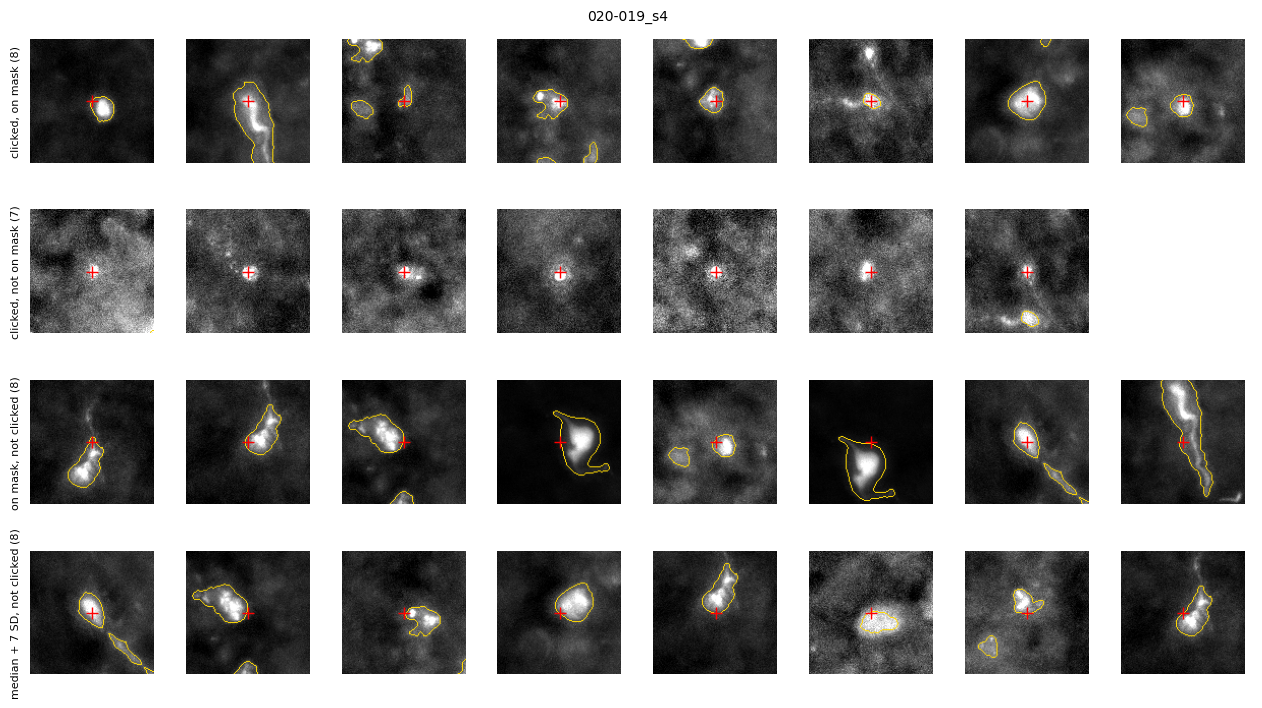

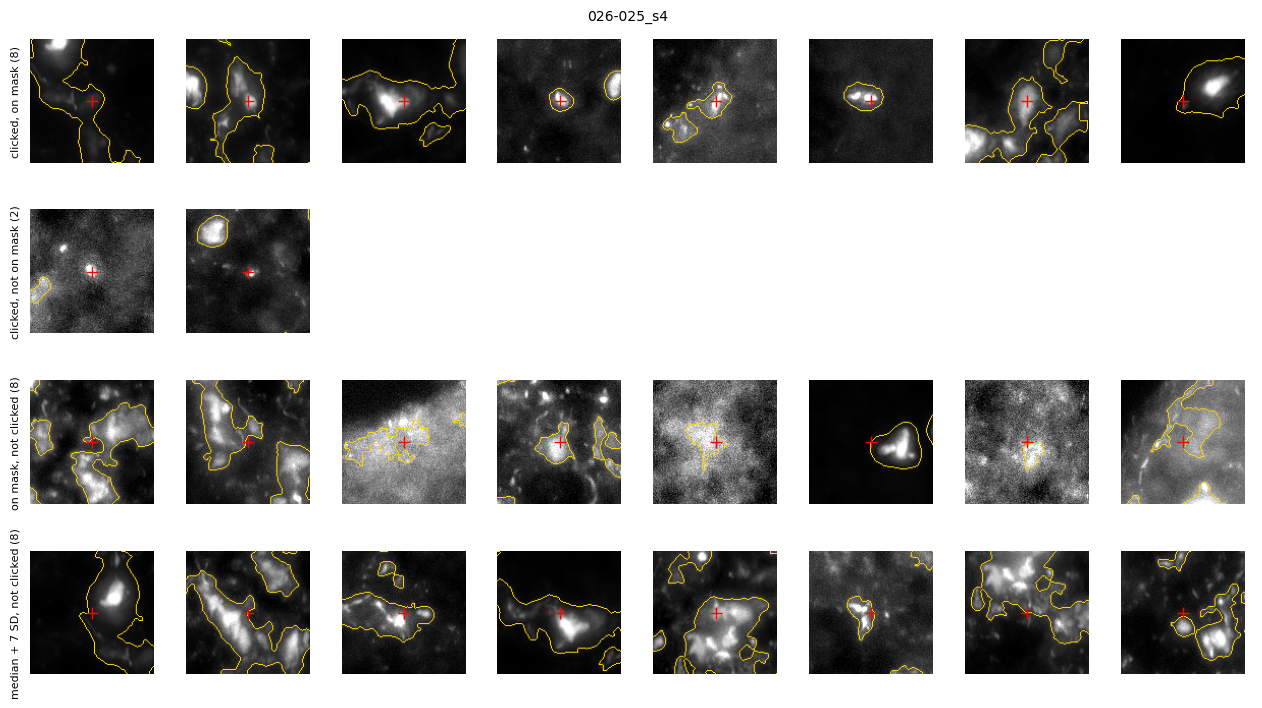

In [12]:
def click_gallery(n, per_row=8, half_um=20.0):
    df = cells_c[n]
    band, reg, d = click_region(n)
    voxel = float(meta_c.loc[n, "voxel"][0])
    half = int(half_um / voxel)
    mask = tifffile.imread(CV.OUT_CLICKED / n / f"{MAIN}.tif") > 0
    reach = ndimage.maximum_filter(mask, size=int(round(6.0 / voxel)) | 1)
    box = ndimage.uniform_filter(mask.astype(np.float32), size=int(round(6.0 / voxel)) | 1)
    specs = loaders.load_path(Path(meta_c.loc[n, "path"]))
    try:
        spec = next(s for s in specs if "488" in str(s.channel_name or s.name))
        whole = (slice(0, int(mask.shape[0])), slice(0, int(mask.shape[1])))
        af = ja._plane(spec, whole).astype(np.float32)
    finally:
        loaders.release(Path(meta_c.loc[n, "path"]))
    dy, dx = d["y (um)"].to_numpy() / voxel, d["x (um)"].to_numpy() / voxel
    on = reach[np.clip(dy.round().astype(int), 0, mask.shape[0] - 1), np.clip(dx.round().astype(int), 0, mask.shape[1] - 1)]
    covered = box[np.clip(df["y"].round().astype(int), 0, mask.shape[0] - 1), np.clip(df["x"].round().astype(int), 0, mask.shape[1] - 1)] >= CV.COVER
    k7 = np.asarray(RULES_C[WANTED["median + 7 SD (median filter)"]](df, band), bool)
    clicked = df["clicked"].to_numpy()
    pick = lambda idx: rng.permutation(np.asarray(idx))[:per_row]
    groups = {
        "clicked, on mask": [(dy[i], dx[i]) for i in pick(np.flatnonzero(on))],
        "clicked, not on mask": [(dy[i], dx[i]) for i in pick(np.flatnonzero(~on))],
        "on mask, not clicked": [(df["y"].iat[i], df["x"].iat[i]) for i in pick(np.flatnonzero(covered & reg & ~clicked))],
        "median + 7 SD, not clicked": [(df["y"].iat[i], df["x"].iat[i]) for i in pick(np.flatnonzero(k7 & reg & ~clicked))],
    }
    fig, axes = plt.subplots(len(groups), per_row, figsize=(1.6 * per_row, 1.8 * len(groups)), squeeze=False)
    for row, (title, items) in zip(axes, groups.items()):
        for k, ax in enumerate(row):
            ax.axis("off")
            if k >= len(items):
                continue
            y, x = int(round(items[k][0])), int(round(items[k][1]))
            win = (slice(max(y - half, 0), y + half), slice(max(x - half, 0), x + half))
            crop = af[win]
            lo, hi = np.percentile(crop, (1, 99.5))
            rgb = np.repeat(np.clip((crop - lo) / max(hi - lo, 1), 0, 1)[..., None], 3, axis=2)
            rgb[find_boundaries(mask[win], mode="inner")] = (1.0, 0.85, 0.0)
            ax.imshow(rgb)
            ax.plot(x - win[1].start, y - win[0].start, "+", color="red", ms=8, mew=1.0)
        row[0].text(-0.08, 0.5, f"{title} ({len(items)})", transform=row[0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
    fig.suptitle(C.short(n), fontsize=10)
    plt.tight_layout()
    plt.show()


for n in CLICKED[:2]:
    click_gallery(n)

### What it showed (27 October 2026: 39 slide scans, 1.73 million Cellpose cells; clicks on 12 earlier samples)

**The AF488 masks and median + 7 SD (median filter) find nearly the same cells; against the clicks, median + 7 SD is still the best rule, and the masks are not better.**

Cell by cell, on the 39 scans (κ: 0 chance, 1 identical):

| | cells called | κ vs median + 3 SD | κ vs median + 7 SD (median filter) | κ vs ring ≥ 1.5 |
|---|---|---|---|---|
| Cellpose + median + 3 SD | 93 888 (5.4 %) | — | 0.32 | 0.13 |
| Cellpose + median + 7 SD (median filter) | 24 747 (1.4 %) | 0.32 | — | 0.44 |
| Cellpose + ring ≥ 1.5 | 12 259 (0.7 %) | 0.13 | 0.44 | — |
| AF488 mask, k = 5 SD | 26 638 covered | 0.30 | **0.79** | 0.41 |
| AF488 mask, k = 8 SD | 12 260 | 0.20 | 0.65 | 0.50 |
| AF488 mask, triangle | 16 539 | 0.23 | 0.71 | 0.47 |

- **k = 5 SD on the background-subtracted AF488 and median + 7 SD on the median-filtered channel are nearly the same rule**: κ 0.79, each finds 77–82 % of the other's cells, and they call almost the same number. Both take a local background away before thresholding — that, not Cellpose, is what decides who is positive.
- **Median + 3 SD stays the odd one out** (κ ≤ 0.37 with everything), calling 4× more cells than median + 7 SD, mostly in haze.

Against Quillan's clicks (822 clicks, 12 samples, his region; scored as in `positivity_metrics`):

| | positive in region | precision | recall | F1 | Spearman vs clicks / mm | median ratio to clicks | clicks within 3 µm of the mask |
|---|---|---|---|---|---|---|---|
| median + 3 SD | 5 686 | 0.06 | 0.57 | 0.11 | 0.28 | 7.3 | — |
| **median + 7 SD (median filter)** | 1 295 | **0.26** | 0.54 | **0.35** | **0.79** | 1.4 | — |
| ring ≥ 1.5 | 1 035 | 0.19 | 0.31 | 0.23 | 0.62 | 1.3 | — |
| AF488 mask, k = 5 SD | 2 548 | 0.13 | 0.56 | 0.22 | 0.62 | 1.8 | 71 % |
| AF488 mask, k = 8 SD | 1 152 | 0.21 | 0.40 | 0.28 | 0.71 | 0.8 | 53 % |
| AF488 mask, triangle | 1 175 | 0.24 | 0.47 | 0.32 | 0.61 | 1.1 | 61 % |

- **Median + 7 SD keeps its place** as the best rule against the clicks (F1 0.35 here; 0.38 in `positivity_metrics`, which scored its own pass of the same cells) and ranks the samples most like them (ρ 0.79). Triangle comes closest (F1 0.32) but ranks the samples less well (ρ 0.61).
- **What the masks miss** ("clicked, not on mask"): small, dim dots — below the 20 µm² smallest object, or under the threshold. **What they add** ("on mask, not clicked"): mostly clear labelled cell bodies, the same kind median + 7 SD calls and the clicks skipped — the clicks are incomplete, so precision understates every rule.
- The shape result stands (section 4): the masks keep each labelled cell's outline — cell bodies off the nucleus, processes 50–130 µm long — which no nucleus-based rule gives.

**Decision.** For *counting*, nothing to gain from the classical masks over median + 7 SD (median filter): same cells, no better against the clicks. Two things follow: (1) **median + 7 SD (median filter) should become the analysis' default** — it is the one rule that wins on every comparison so far; today the panel's default is median + 3 SD, and it offers no median-filtered measurement at all; (2) the AF488 mask is worth adding as an **outline** for the positive cells (their real shape, for pictures and morphology), not as the rule that calls them. Nothing changed in the analysis yet.


### Follow-up (28 October 2026): both changes made in the analysis

- **Median + 7 SD on the median-filtered mean is now the Cells panel's default** (`junction_analysis.FILTERED`, `K_SD = 7`): every cell gets `<channel> mean (median filter)` — its mean less the channel's median over 45 µm, worked out once over the whole section at 1/8 and scaled up per tile. Re-scoring three of the slide scans above with the panel's engine gives the notebook's numbers exactly: same threshold (107.5, 107.6, 94.8), same positives in the region (1, 33, 54) and in the section (531, 658, 637), per-cell values identical. Cells saved before have the figure measured from their grown label map when re-scored (~12 s a slide scan, nothing segmented).
- **The AF488 mask (k = 5 SD) now outlines the positive cells** (`positive_shapes`): each piece of the mask touching a positive cell's grown region is joined to it, a piece touching two shared out to the nearer. Drawing only — a layer per channel, an outline in the section picture, `labels/<sample> <channel> shape.tif`; which cells are positive does not change. ~5 s a slide scan.
